# Imports

In [1]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from tqdm import tqdm
import subprocess

import os, sys
sys.path.append("D:\\DATA\\ActivePIC")
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

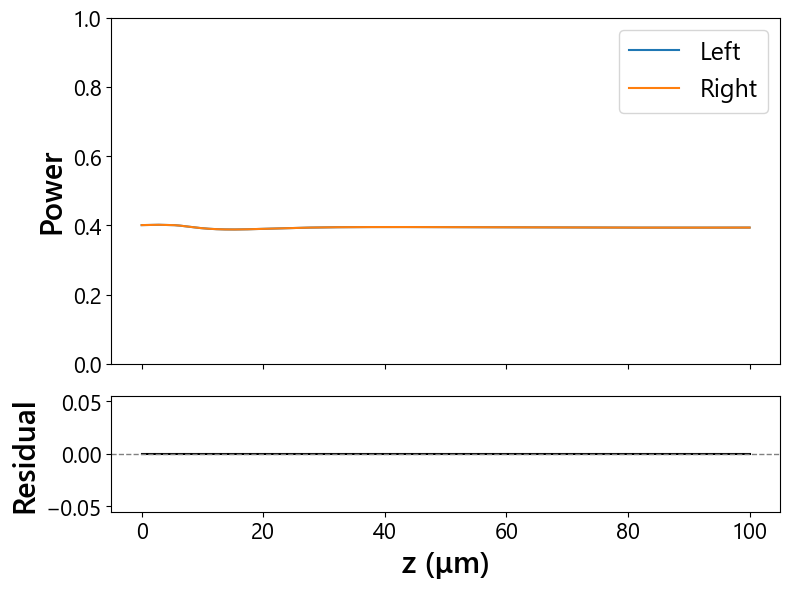

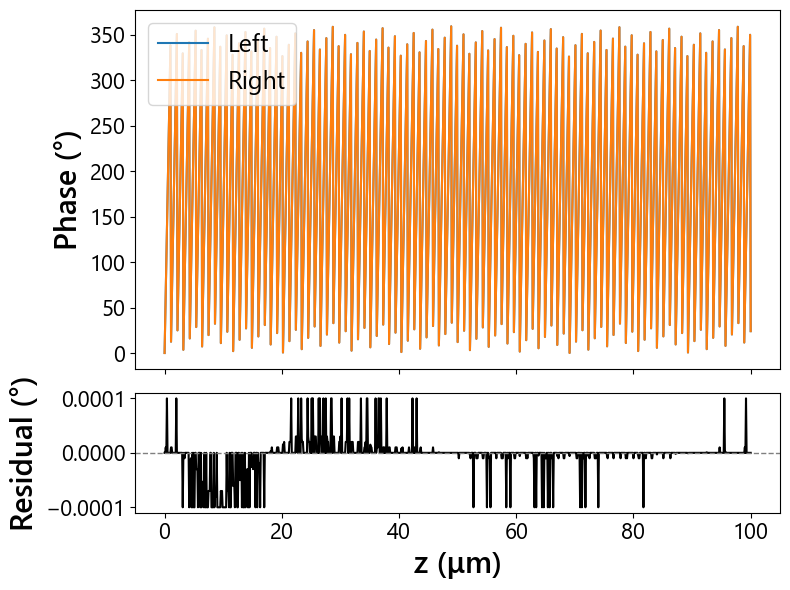

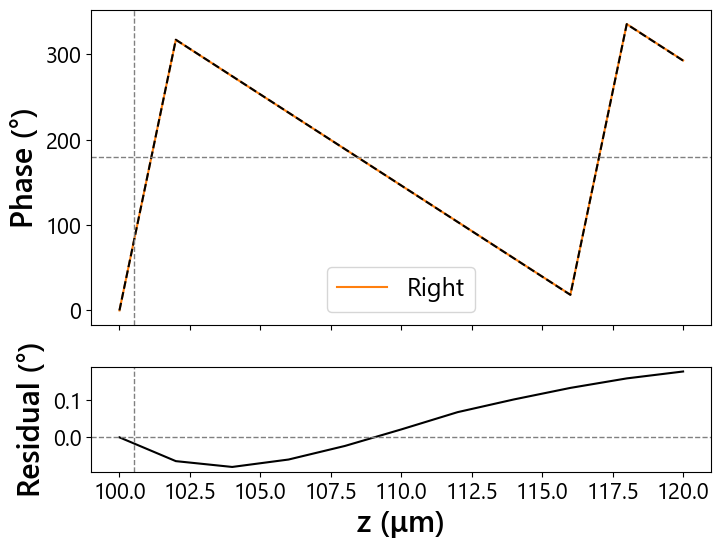

In [30]:
filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguide_BPmode_Length.mon'
monitors = rlib.read_monitor(filename_BP)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(monitors.z, monitors.values[:, 0], label='Left')
ax1.plot(monitors.z, monitors.values[:, 2], label='Right')
ax1.set_ylabel('Power')
ax1.set_ylim(0, 1)
ax1.legend()
 
residual = monitors.values[:, 0] - monitors.values[:, 2]
ax2.plot(monitors.z, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual')
 
plt.tight_layout()
plt.show()


fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(monitors.z, monitors.values[:, 1], label='Left')
ax1.plot(monitors.z, monitors.values[:, 3], label='Right')
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = monitors.values[:, 1] - monitors.values[:, 3]
ax2.plot(monitors.z, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual (°)')
 
plt.tight_layout()
plt.show()

filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_FiberMode_LengthMod.mon'
monitors = rlib.read_monitor(filename_BP)
Neff, wav = 1.458035005, 1.55
phase_sim = monitors.values[:, 3]-monitors.values[0, 1]
phase_est = 180/np.pi * (2*np.pi/wav) * Neff * (monitors.z - monitors.z[0])
phase_est = phase_est % 360
dLength_pi = wav/(2*Neff) + monitors.z[0]

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)
 
ax1.plot(monitors.z, phase_sim, label='Right', color='C1')
ax1.plot(monitors.z, phase_est, color='k', linestyle='dashed')
ax1.axvline(dLength_pi, color='grey', linestyle='dashed', linewidth=1)
ax1.axhline(180, color='grey', linestyle='dashed', linewidth=1)
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = phase_sim - phase_est
ax2.plot(monitors.z, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.axvline(dLength_pi, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual (°)')
 
# # Inset: zoom into the last 0.1 microns of z
# z_max = monitors.z.max()
# axins = inset_axes(ax1, width="35%", height="45%", loc='upper left', borderpad=2)
 
# mask = monitors.z >= (z_max - 0.1)
# axins.plot(monitors.z, residual, color='k')
# axins.axhline(0, color='grey', linestyle='dashed', linewidth=1)
# axins.set_xlim(z_max - 0.01, z_max+0.01)
# # axins.set_ylim(179, 181)
 
plt.show()


In [ ]:
import numpy as np

filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_FemSIM_LengthMod_FilePower.mon'
monitors = rlib.read_monitor(filename_BP)
Neff, wav = 1.457897067, 1.55
phase_sim = ((monitors.values[:, 3]-monitors.values[0, 1]) + 360)%360
phase_est = 180/np.pi * (2*np.pi/wav) * Neff * (monitors.z - monitors.z[0])
phase_est = phase_est % 360
dLength_pi = wav/(2*Neff) + monitors.z[0]

def extract_s(z, phase_monitor_deg, phase_expected_deg):
    """
    z: 1D array, propagation distance (µm) for ONE wavelength
    phase_monitor_deg: BeamPROP phase at each z, wrapped 0-360 (deg) - the orange points
    phase_expected_deg: predicted phase at each z, wrapped 0-360 (deg) - the black dashed line
    Returns: s (slope), intercept (deg, should be ~0 if no launch-phase offset)
    """
    # unwrap needs radians
    monitor_unwrapped = np.degrees(np.unwrap(np.radians(phase_monitor_deg)))
    expected_unwrapped = np.degrees(np.unwrap(np.radians(phase_expected_deg)))

    # fit monitor = s * expected + intercept  (free intercept - don't force through
    # origin, since a nonzero intercept here is itself diagnostic: it's the
    # launch/coupling phase offset the multi-step method exists to isolate)
    A = np.vstack([expected_unwrapped, np.ones_like(expected_unwrapped)]).T
    s, intercept = np.linalg.lstsq(A, monitor_unwrapped, rcond=None)[0]
    return s, intercept

# If you have this per wavelength (e.g. z_arr same for all, phase arrays shape (n_wav, n_z)):
s_vals = np.zeros_like(wav_arr, dtype=float)
intercepts = np.zeros_like(wav_arr, dtype=float)
for i in range(len(wav_arr)):
    s_vals[i], intercepts[i] = extract_s(z_arr, phase_monitor_all[i], phase_expected_all[i])

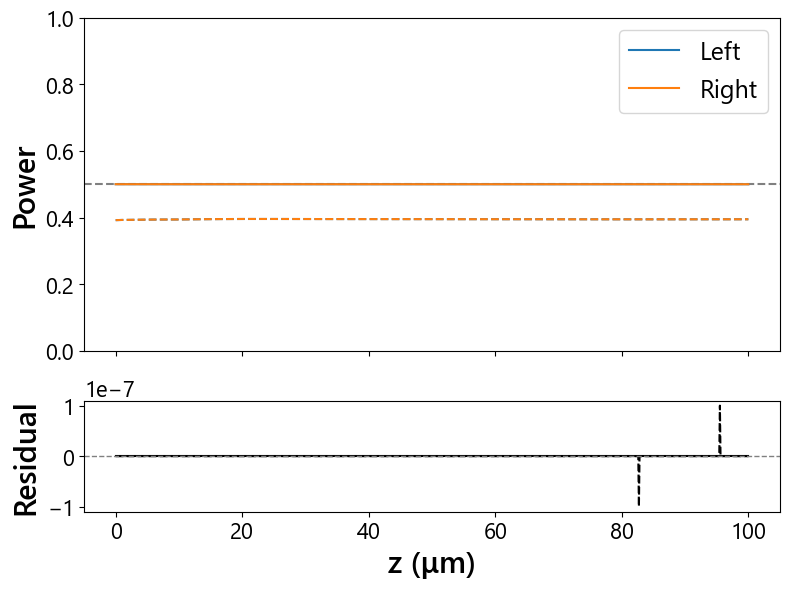

0.0


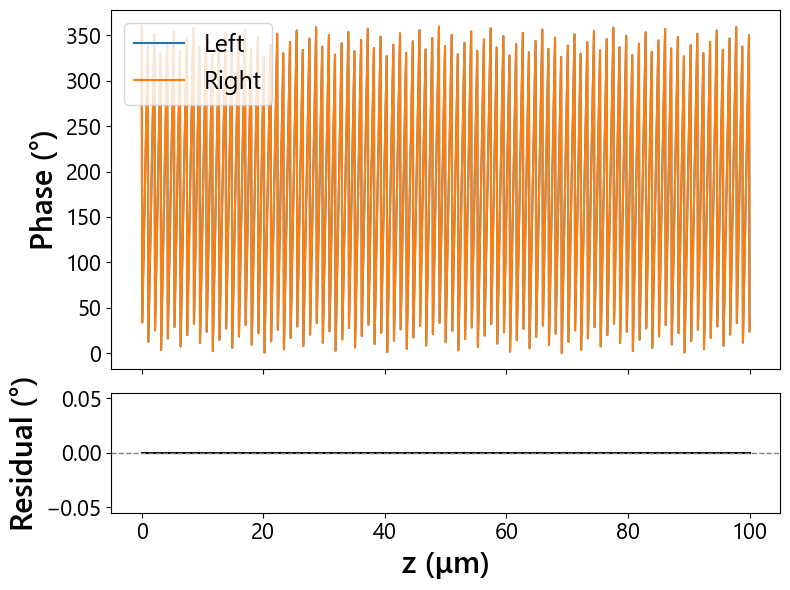

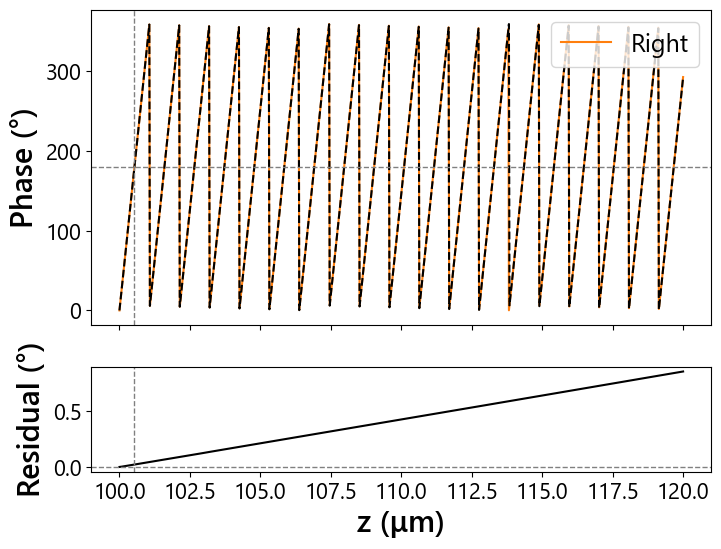

In [77]:
filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_FemSIM_Length_FilePower.mon'
monitors = rlib.read_monitor(filename_BP)
filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_FemSIM_Length_PartialPower.mon'
monitors_partial = rlib.read_monitor(filename_BP)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(monitors.z, monitors.values[:, 0], label='Left', zorder=1)
ax1.plot(monitors.z, monitors.values[:, 2], label='Right', zorder=1)
ax1.plot(monitors.z, monitors_partial.values[:, 0], color='C0', linestyle='dashed', zorder=1)
ax1.plot(monitors.z, monitors_partial.values[:, 2], color='C1', linestyle='dashed', zorder=1)
ax1.axhline(0.5, color='gray', linestyle='dashed', zorder=0)
ax1.set_ylabel('Power')
ax1.set_ylim(0, 1)
ax1.legend()
 
residual = monitors.values[:, 0] - monitors.values[:, 2]
residual_partial = monitors_partial.values[:, 0] - monitors_partial.values[:, 2]
ax2.plot(monitors.z, residual, color='k')
ax2.plot(monitors.z, residual_partial, color='k', linestyle='dashed')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual')
 
plt.tight_layout()
plt.show()
print(np.sum(residual))


fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(monitors.z, monitors.values[:, 1], label='Left')
ax1.plot(monitors.z, monitors.values[:, 3], label='Right')
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = monitors.values[:, 1] - monitors.values[:, 3]
ax2.plot(monitors.z, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual (°)')
 
plt.tight_layout()
plt.show()

filename_BP = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_FemSIM_LengthMod_FilePower.mon'
monitors = rlib.read_monitor(filename_BP)
Neff, wav = 1.457897067, 1.55
phase_sim = ((monitors.values[:, 3]-monitors.values[0, 1]) + 360)%360
phase_est = 180/np.pi * (2*np.pi/wav) * Neff * (monitors.z - monitors.z[0])
phase_est = phase_est % 360
dLength_pi = wav/(2*Neff) + monitors.z[0]

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)
 
ax1.plot(monitors.z, phase_sim, label='Right', color='C1')
ax1.plot(monitors.z, phase_est, color='k', linestyle='dashed')
ax1.axvline(dLength_pi, color='grey', linestyle='dashed', linewidth=1)
ax1.axhline(180, color='grey', linestyle='dashed', linewidth=1)
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = phase_sim - phase_est
residual[residual > 180] = residual[residual > 180] - 360 
residual[residual < -180] = residual[residual < -180] + 360 
ax2.plot(monitors.z, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.axvline(dLength_pi, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('z (μm)')
ax2.set_ylabel('Residual (°)')
 
# # Inset: zoom into the last 0.1 microns of z
# z_max = monitors.z.max()
# axins = inset_axes(ax1, width="35%", height="45%", loc='upper left', borderpad=2)
 
# mask = monitors.z >= (z_max - 0.1)
# axins.plot(monitors.z, residual, color='k')
# axins.axhline(0, color='grey', linestyle='dashed', linewidth=1)
# axins.set_xlim(z_max - 0.01, z_max+0.01)
# # axins.set_ylim(179, 181)
 
plt.show()


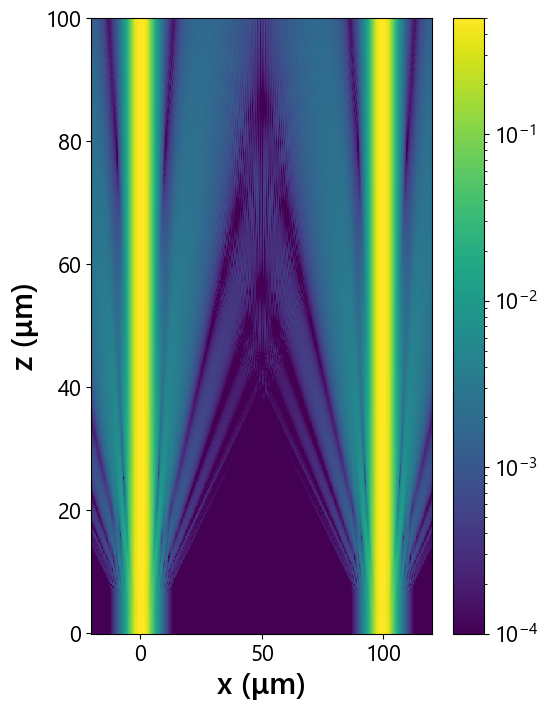

In [85]:
import linecache
from matplotlib.colors import LogNorm

# Constructive interference
filename = 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_FiberMode_Length_xz.dat'
data = np.genfromtxt(filename, delimiter='', skip_header=6)[:, 1:].T
x_line = linecache.getline(filename, 4)
y_line = linecache.getline(filename, 5)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

fig, ax = plt.subplots(1, 1, figsize=(6, 8), sharey=True)
fig.subplots_adjust(left=0.15, right=0.86, wspace=0.1)
 
vmax = 0.5
vmin = 1e-4  # floor value -- log scale can't include 0, adjust based on your data's noise floor
 
im = ax.pcolormesh(x, y, np.clip(data, vmin, None), norm=LogNorm(vmin=vmin, vmax=vmax))
 
ax.set_xlabel('x (μm)')
ax.set_ylabel('z (μm)')
 
plt.colorbar(im)
 
plt.show()

# Loop through injection offsets

In [79]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
save_dir = f"{working_dir}TwoWaveguides_scan_injectionOffset\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "TwoWaveguides"
filename = f"{filename_root}.ind"

# Define parameter scan
offset_arr = np.linspace(-1, 1, 21)
wav_arr = np.linspace (1.45, 1.65, 5)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    print(f'Wavelength: {wav} microns')
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for offset in tqdm(offset_arr, desc='Injection offset loop', position=0, leave=False):
        offset_str = f"{offset:0.3f}".replace(".", "p").replace("-","n")

        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("LaunchOffsetFactor", offset)
        c.write(working_dir+filename)

        command = ["bsimw32", "-min", filename, 
                   f"prefix={save_dir}/{filename_root}_Wav{wav_str}_OffsetFactor{offset_str}", "wait=0"]

        print(f'Wavelength written: {rlib.read_symbol(working_dir+filename, "free_space_wavelength")}')
        print(f'Offset factor written: {rlib.read_symbol(working_dir+filename, "LaunchOffsetFactor")}')
        
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

        metadata_name = f'{save_dir}{filename_root}_Wav{wav_str}_OffsetFactor{offset_str}.json'
        symbols = rlib.export_symbols(working_dir+filename, metadata_name)

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)
np.save(f"{save_dir}{filename_root}_OffsetFactor.npy", offset_arr)

Wavelength loop:   0%|          | 0/5 [00:00<?, ?it/s]

Wavelength: 1.45 microns


Injection offset loop:   0%|          | 0/21 [00:00<?, ?it/s]

Wavelength written: 1.45
Offset factor written: -1


Injection offset loop:   5%|▍         | 1/21 [02:22<47:22, 142.12s/it]

Wavelength written: 1.45
Offset factor written: -0.9


... (210 outputs left out)

Injection offset loop:  90%|█████████ | 19/21 [46:01<04:52, 146.28s/it]

Wavelength written: 1.65
Offset factor written: 0.9


Injection offset loop:  95%|█████████▌| 20/21 [48:27<02:26, 146.23s/it]

Wavelength written: 1.65
Offset factor written: 1


Wavelength loop:   0%|          | 0/5 [00:00<?, ?it/s]

Wavelength: 1.45 microns


Wavelength: 1.5 microns


Wavelength loop:  40%|████      | 2/5 [00:00<00:00, 10.72it/s]

Wavelength: 1.5499999999999998 microns


Wavelength: 1.5999999999999999 microns


Wavelength loop:  80%|████████  | 4/5 [00:00<00:00,  9.60it/s]         

Wavelength: 1.65 microns


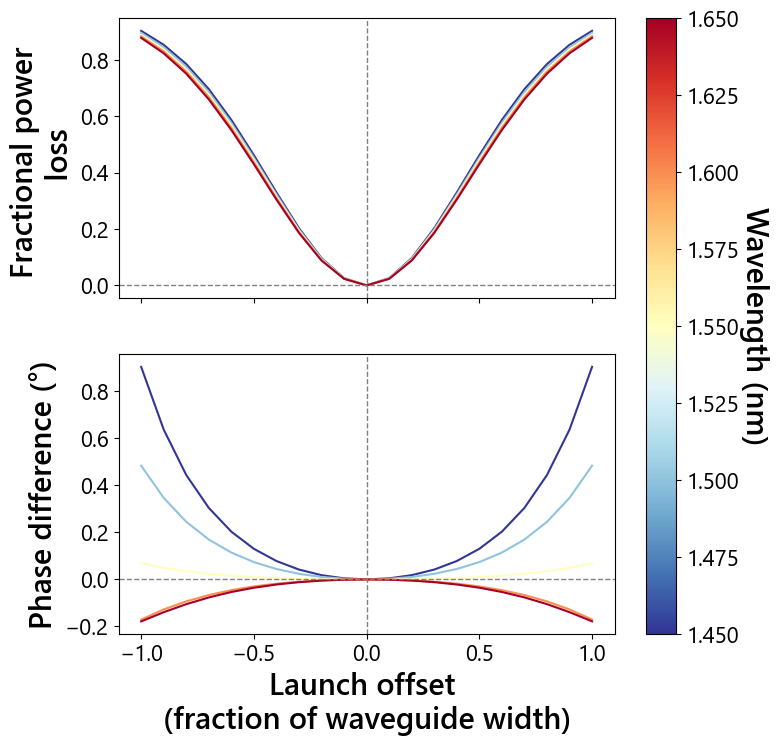

In [84]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
save_dir = f"{working_dir}TwoWaveguides_scan_injectionOffset\\"
filename_root = "TwoWaveguides"
filename = f"{filename_root}.ind"

# Define parameter scan
wav_arr = np.load(f"{save_dir}{filename_root}_Wav.npy")
offset_arr = np.load(f"{save_dir}{filename_root}_OffsetFactor.npy")
monitors_arr = []
for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    print(f'Wavelength: {wav} microns')
    wav_str = f"{wav:0.3f}".replace(".", "p")
    monitor_arr = []
    for offset in tqdm(offset_arr, desc='Injection offset loop', position=0, leave=False):
        offset_str = f"{offset:0.3f}".replace(".", "p").replace("-","n")
        monitor_file = f"{save_dir}{filename_root}_Wav{wav_str}_OffsetFactor{offset_str}.mon"

        monitor = rlib.read_monitor(monitor_file)
        monitor_arr.append(monitor.values[-1])
    monitors_arr.append(monitor_arr)
monitors_arr = np.array(monitors_arr)


import matplotlib.cm as cm
from matplotlib.colors import Normalize

cmap = plt.get_cmap('RdYlBu_r')
norm = Normalize(vmin=min(wav_arr), vmax=max(wav_arr))
 
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 8), sharex=True,
    gridspec_kw={'height_ratios': [1, 1]}
)
 
power_diff = 1 - monitors_arr[:, :, 2] / monitors_arr[:, :, 0]
phase_diff = monitors_arr[:, :, 1] - monitors_arr[:, :, 3]
 
for i, w in enumerate(wav_arr):
    ax1.plot(offset_arr, power_diff[i], color=cmap(norm(w)))
ax1.axvline(0, color='grey', linestyle='dashed', linewidth=1)
ax1.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax1.set_ylabel('Fractional power \n loss')
 
for i, w in enumerate(wav_arr):
    ax2.plot(offset_arr, phase_diff[i], color=cmap(norm(w)))
ax2.axvline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Launch offset \n(fraction of waveguide width)')
ax2.set_ylabel('Phase difference (°)')
 
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=[ax1, ax2])
cbar.set_label('Wavelength (nm)', rotation=270, labelpad=22)
 
plt.show()
 

# BeamPROP repeatability

In [3]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
save_dir = f"{working_dir}TwoWaveguides_repeatability\\"
os.makedirs(save_dir, exist_ok=True)
filename_root = "TwoWaveguides"
filename = f"{filename_root}.ind"

# Define parameter scan
wav = 1.55
offset = 0

monitor_arr = []

for trial in tqdm(np.arange(30), desc='Trial loop', position=0, leave=False):  
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("LaunchOffsetFactor", offset)
        c.write(working_dir+filename)

        command = ["bsimw32", "-min", filename, 
                        f"prefix={save_dir}/{filename_root}_repeatability", "wait=0"]

        print(f'Wavelength written: {rlib.read_symbol(working_dir+filename, "free_space_wavelength")}')
        print(f'Offset factor written: {rlib.read_symbol(working_dir+filename, "LaunchOffsetFactor")}')

        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

        metadata_name = f'{save_dir}{filename_root}_repeatability.json'
        symbols = rlib.export_symbols(working_dir+filename, metadata_name)

        monitor_file = f"{save_dir}{filename_root}_repeatability.mon"
        monitor = rlib.read_monitor(monitor_file)
        monitor_arr.append(monitor.values[-1])
monitor_arr = np.array(monitor_arr)

Trial loop:   0%|          | 0/30 [00:00<?, ?it/s]

Wavelength written: 1.55
Offset factor written: 0


Trial loop:   3%|▎         | 1/30 [02:17<1:06:32, 137.66s/it]

Wavelength written: 1.55
Offset factor written: 0


Trial loop:   7%|▋         | 2/30 [04:37<1:04:46, 138.82s/it]

Wavelength written: 1.55
Offset factor written: 0


... (50 outputs left out)

Trial loop:  93%|█████████▎| 28/30 [1:05:52<04:42, 141.46s/it]

Wavelength written: 1.55
Offset factor written: 0


Trial loop:  97%|█████████▋| 29/30 [1:08:12<02:20, 140.84s/it]

Wavelength written: 1.55
Offset factor written: 0


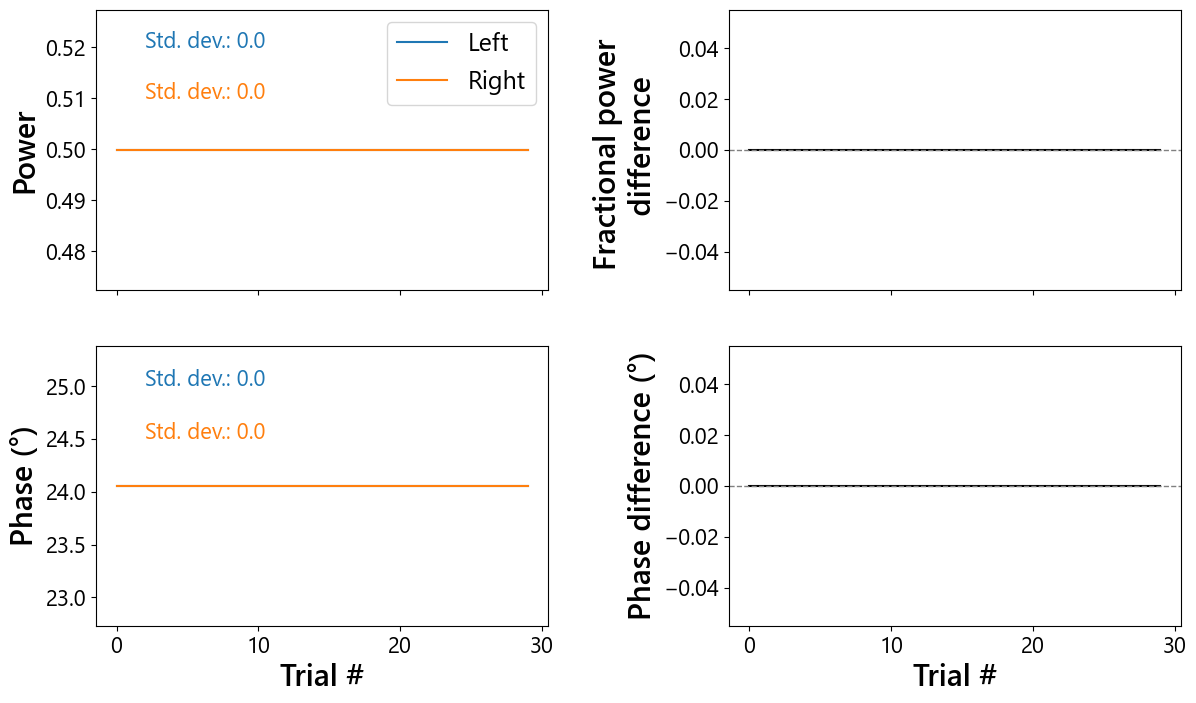

In [14]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize

monitor_arr = np.array(monitor_arr)

fig, axes = plt.subplots(
    2, 2, figsize=(14, 8), sharex=True,
    gridspec_kw={'height_ratios': [1, 1]}
)
plt.subplots_adjust(wspace=0.4)
(ax_p_raw, ax_p_diff), (ax_ph_raw, ax_ph_diff) = axes

power_diff = 1 - monitor_arr[:, 2] / monitor_arr[:, 0]
phase_diff = monitor_arr[:, 1] - monitor_arr[:, 3]

# --- Column 1: raw power and phase ---
ax_p_raw.plot(monitor_arr[:, 0], label='Left')
ax_p_raw.plot(monitor_arr[:, 2], label='Right')
ax_p_raw.text(2, 0.52, f'Std. dev.: {np.std(monitor_arr[:, 0])}', color='C0', fontsize=16)
ax_p_raw.text(2, 0.51, f'Std. dev.: {np.std(monitor_arr[:, 2])}', color='C1', fontsize=16)
ax_p_raw.set_ylabel('Power')
ax_p_raw.legend()

ax_ph_raw.plot(monitor_arr[:, 1])
ax_ph_raw.plot(monitor_arr[:, 3])
ax_ph_raw.text(2, 25, f'Std. dev.: {np.std(monitor_arr[:, 1]):.1f}', color='C0', fontsize=16)
ax_ph_raw.text(2, 24.5, f'Std. dev.: {np.std(monitor_arr[:, 3]):.1f}', color='C1', fontsize=16)
ax_ph_raw.set_xlabel('Trial #')
ax_ph_raw.set_ylabel('Phase (°)')

# --- Column 2: differences ---
ax_p_diff.plot(power_diff, 'k')
ax_p_diff.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax_p_diff.set_ylabel('Fractional power \n difference')


ax_ph_diff.plot(phase_diff, 'k')
ax_ph_diff.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax_ph_diff.set_xlabel('Trial #')
ax_ph_diff.set_ylabel('Phase difference (°)')

plt.show()

In [9]:
from matplotlib.ticker import ScalarFormatter
import imageio.v2 as imageio


working_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\"
save_dir = f"{working_dir}StraightWaveguide_simulatedBend_scan_gridSize_gridEdgeFactor\\"
filename_root = "StraightWaveguide_simulatedBend"

gif_path = os.path.join(save_dir, f"{filename_root}_neff_convergence.gif")
frame_dir = os.path.join(save_dir, "gif_frames")
os.makedirs(frame_dir, exist_ok=True)

# wav_arr = np.load(f"{save_dir}{filename_root}_Wav.npy")
# grid_size_arr = np.load(f"{save_dir}{filename_root}_GridSize.npy")
# grid_edge_arr = np.load(f"{save_dir}{filename_root}_GridEdge.npy")

grid_size_arr = [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, *np.arange(0.1, 1.1, 0.1)]
# grid_size_arr = [0.01, 0.02, 0.03, 0.04]
grid_edge_arr = np.arange(0.1, 1.1, 0.1)
wav_arr = np.linspace (1.45, 1.65, 5)[:1]

n_wav, n_size, n_edge = len(wav_arr), len(grid_size_arr), len(grid_edge_arr)

neff_cube = np.full((n_wav, n_size, n_edge), np.nan)

np.save(f"{save_dir}{filename_root}_neff.npy", neff_cube)

for iw, wav in enumerate(wav_arr):
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for isz, grid_size in enumerate(grid_size_arr):
        grid_size_str = f"{grid_size:0.3f}".replace(".", "p")
        for ied, grid_edge in enumerate(grid_edge_arr):
            grid_edge_str = f"{grid_edge:0.3f}".replace(".", "p")
            fn = (f'{save_dir}{filename_root}_Wav{wav_str}_GridSize{grid_size_str}'
                  f'_GridEdge{grid_edge_str}.nef')
            try:
                sim = np.genfromtxt(fn)
                neff_cube[iw, isz, ied] = sim[0,1]
            except (FileNotFoundError, IndexError, OSError):
                pass  # left as NaN

n_missing = np.isnan(neff_cube).sum()
if n_missing:
    print(f"Warning: {n_missing} of {neff_cube.size} (wav, grid_size, grid_edge) "
          f"combinations had no readable .nef file and will show as blank cells.")

size_labels = [f"{v:.3f}" for v in grid_size_arr]
edge_labels = [f"{v:.2f}" for v in grid_edge_arr]

frame_paths = []
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color="lightgray")  # missing (.nef not found) cells

for iw, wav in enumerate(wav_arr):
    fig, ax = plt.subplots(figsize=(9,9.5))

    vmin = np.nanmax(neff_cube[iw]) - 1e-4 #np.percentile(neff_cube[iw], 99)
    vmax = np.nanmax(neff_cube[iw])

    im = ax.imshow(
        neff_cube[iw],           # shape (n_size, n_edge)
        origin="lower",
        aspect="equal",          # every cell literally square
        vmin=vmin, vmax=vmax,
        cmap=cmap,
        interpolation="nearest",
    )

    ax.set_xticks(range(n_edge))
    ax.set_xticklabels(edge_labels, rotation=45, ha="right")
    ax.set_yticks(range(n_size))
    ax.set_yticklabels(size_labels)

    ax.set_xlabel("Grid Edge factor")
    ax.set_ylabel("Grid Size (\u03bcm)")
    ax.set_title(f"\u03bb = {wav:.3f} \u03bcm")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(r"$n_{\mathrm{eff}}$", rotation=270, labelpad=20)

    fmt = ScalarFormatter(useOffset=False)
    fmt.set_scientific(False)
    cbar.ax.yaxis.set_major_formatter(fmt)
 
    frame_path = os.path.join(frame_dir, f"frame_{iw:03d}.png")
    fig.savefig(frame_path, dpi=120)   # no tight_layout/bbox_inches="tight" -- fixed axes instead
    plt.close(fig)
    frame_paths.append(frame_path)
 
# --------------------------------------------------------------------- #
# Assemble into a GIF
# --------------------------------------------------------------------- #
frames = [imageio.imread(p) for p in frame_paths]
 
# Safety net: even with fixed figsize/dpi, matplotlib can occasionally
# round to a slightly different pixel count between frames. If that
# happens, crop every frame down to the smallest common height/width
# rather than letting mimsave fail outright.
shapes = {f.shape for f in frames}
if len(shapes) > 1:
    min_h = min(f.shape[0] for f in frames)
    min_w = min(f.shape[1] for f in frames)
    print(f"Warning: frames had inconsistent shapes {shapes}; "
            f"cropping all frames to ({min_h}, {min_w}).")
    frames = [f[:min_h, :min_w] for f in frames]

imageio.mimsave(gif_path, frames, fps=0.5, loop=0)  # 1 s/frame, loop forever

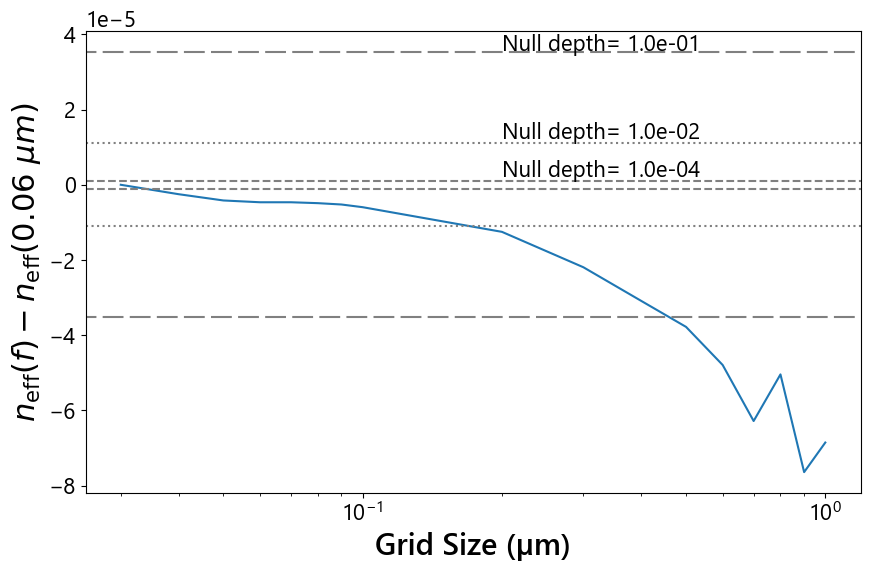

In [8]:
ind_grid_size = int(np.argwhere(np.isclose(grid_size_arr, 0.1)))
ind_grid_edge = int(np.argwhere(np.isclose(grid_edge_arr, 0.1)))
 
fig, ax = plt.subplots(figsize=(10, 6))
 
y = neff_cube[:, :, ind_grid_edge] - neff_cube[:, 0, ind_grid_edge][:, None]
 
for i, w in enumerate(wav_arr):
    ax.semilogx(grid_size_arr, y[i])#, color=cmap(norm(w)))
 
ntable = np.loadtxt(f'D:\\DATA\\SURF_2026\\ConvergenceTest\\Neff_tolerance.txt', delimiter=',', skiprows=1)
 
ax.axhline(ntable[0, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(ntable[1, 1], linestyle="dotted", color="grey")
ax.axhline(ntable[3, 1], linestyle="dashed", color="grey")
 
ax.axhline(-ntable[0, 1], linestyle=(5, (10, 3)), color="grey")
ax.axhline(-ntable[1, 1], linestyle="dotted", color="grey")
ax.axhline(-ntable[3, 1], linestyle="dashed", color="grey")
 
ax.text(0.2, ntable[0, 1]*1.01, f"Null depth= {ntable[0, 0]:0.1e}", fontsize=16)
ax.text(0.2, ntable[1, 1]*1.1, f"Null depth= {ntable[1, 0]:0.1e}", fontsize=16)
ax.text(0.2, ntable[3, 1]*1.9, f"Null depth= {ntable[3, 0]:0.1e}", fontsize=16)
 
ax.set_xlabel("Grid Size (µm)")
ax.set_ylabel(r"$n_{\rm eff}(f) - n_{\rm eff}(0.06\ µm)$")
 
 
plt.show()

# Two waveguide test: different lengths to validate phase metric

In [2]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
filename_root = "TwoWaveguides_lengthTest"
save_dir = f"{working_dir}TwoWaveguides_lengthTest_pade44_scan_Wav\\"
os.makedirs(save_dir, exist_ok=True)
CAD_path = f"{working_dir}{filename_root}.ind"

# Define parameter scan
wav_arr = np.linspace(1.45, 1.65, 3)

for wav in tqdm(wav_arr, desc='Wavelength loop', leave=False):
    wav_str = rlib.param_str(wav)
    mode_filename = f"{working_dir}StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00"
    if not os.path.exists(mode_filename):
        raise FileNotFoundError(mode_filename)

    rlib.run_sim(
        CAD_path,
        prefix=f"{save_dir}{filename_root}_scan_Wav{wav_str}",
        symbols={
            "free_space_wavelength": wav,
            "Mode_filename_left": mode_filename,
            "Mode_filename_right": mode_filename,
            "pade_order": 4,
            "pade_order_warning_3d": 0,
        },
        keep_ext=None,                      # keep every output file, as your original script did
    )

np.save(f"{save_dir}{filename_root}_pade44_Wav.npy", wav_arr)

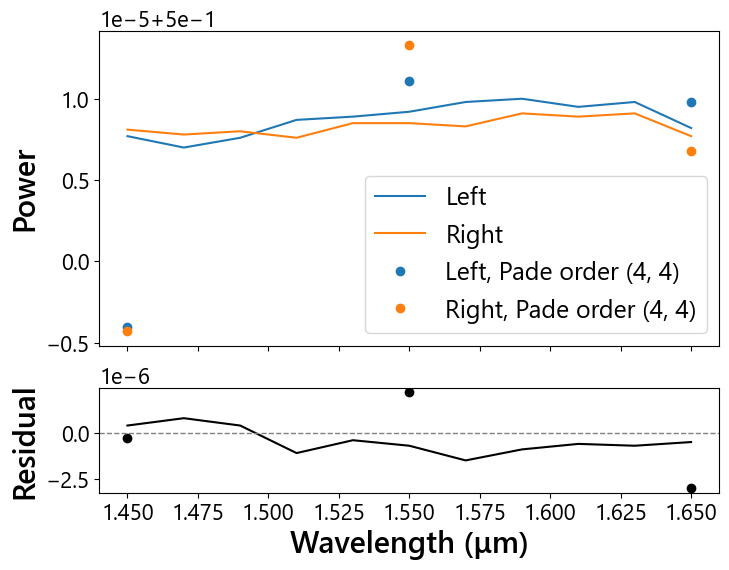

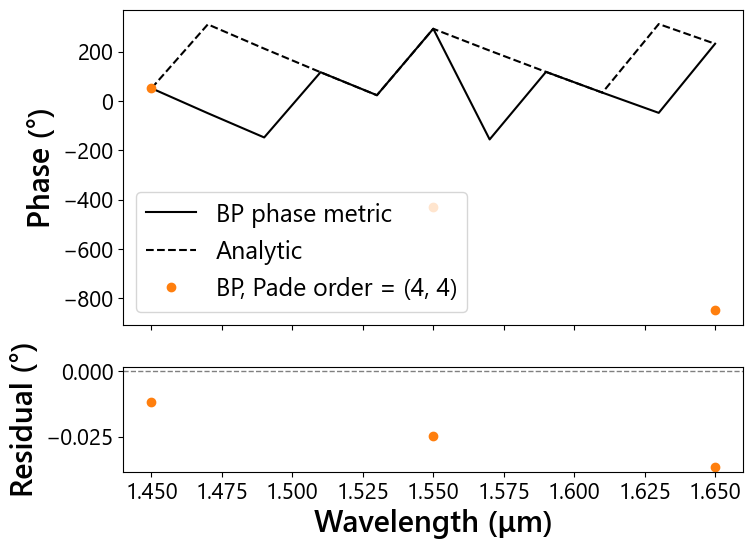

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import rsoft_lib as rlib

working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
filename_root = "TwoWaveguides"
save_dir = f"{working_dir}TwoWaveguides_lengthTest_scan_Wav\\"                 # the original scan (11 wavelengths)
save_dir_pade44 = f"{working_dir}TwoWaveguides_lengthTest_pade44_scan_Wav\\"    # the Pade (4,4) points (3 wavelengths)
table_filename = r"D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table\StraightWaveguide_neff.csv"
df_neff = pd.read_csv(table_filename)
wav_arr = np.linspace(1.45, 1.65, 11)
wav_pade44 = np.linspace(1.45, 1.65, 3)


def load_points(folder, wavs):
    """Monitor values (left power and phase at z = 100, right power and phase at z = 120) and the analytic phase difference."""
    monitors, phase_expected = [], []
    for wav in wavs:
        match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], 3.40)]
        neff = match.iloc[0]['neff']                                               # both guides are 3.4 um wide
        phase_expected.append((2 * np.pi / wav * neff * (120 - 100)) * 180 / np.pi)
        monitor = rlib.read_monitor(f"{folder}{filename_root}_lengthTest_scan_Wav{rlib.param_str(wav)}.mon")
        monitors.append(np.hstack([monitor.values[np.isclose(monitor.z, 100.0)].flatten()[:2],
                                   monitor.values[np.isclose(monitor.z, 120.0)].flatten()[2:]]))
    return np.array(monitors), np.array(phase_expected) % 360


wrap = lambda x: (x + 180) % 360 - 180                                              # to (-180, 180]
monitors, phase_diff_expected = load_points(save_dir, wav_arr)
monitors44, phase_diff_expected44 = load_points(save_dir_pade44, wav_pade44)

# ---- power
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(wav_arr, monitors[:, 0], label='Left', color='C0')
ax1.plot(wav_arr, monitors[:, 2], label='Right', color='C1')
ax1.plot(wav_pade44, monitors44[:, 0], 'o', color='C0', label='Left, Pade order (4, 4)')
ax1.plot(wav_pade44, monitors44[:, 2], 'o', color='C1', label='Right, Pade order (4, 4)')
ax1.set_ylabel('Power')
ax1.legend()

ax2.plot(wav_arr, monitors[:, 2] - monitors[:, 0], color='k')
ax2.plot(wav_pade44, monitors44[:, 2] - monitors44[:, 0], 'o', color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual')
plt.show()

# ---- phase
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

phase_diff_monitor = monitors[:, 3] - monitors[:, 1]
phase_unwrapped = np.unwrap(phase_diff_monitor, period=360)
ax1.plot(wav_arr, phase_unwrapped, 'k', label='BP phase metric')
ax1.plot(wav_arr, np.unwrap(phase_diff_expected, period=360), 'k--', label='Analytic')
# ax1.plot(wav_arr, phase_diff_monitor, 'k', label='BP phase metric')
# ax1.plot(wav_arr, phase_diff_expected, 'k--', label='Analytic')

phase_diff_monitor44 = monitors44[:, 3] - monitors44[:, 1]
branch = np.interp(wav_pade44, wav_arr, phase_unwrapped)                            # put the (4,4) points on the same 360-degree branch
phase44 = phase_diff_monitor44 + 360 * np.round((branch - phase_diff_monitor44) / 360)
ax1.plot(wav_pade44, phase44, 'o', color='C1', label='BP, Pade order = (4, 4)')
ax1.set_ylabel('Phase (°)')
ax1.legend()

# ax2.plot(wav_arr, wrap(phase_diff_monitor - phase_diff_expected), color='k')
ax2.plot(wav_pade44, wrap(phase_diff_monitor44 - phase_diff_expected44), 'o', color='C1')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual (°)')
plt.show()

# Two waveguide test: different widths to validate phase metric

In [28]:
import shutil
from pathlib import Path

source_dir = Path(r'D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table')
dest_dir = Path(r'D:\DATA\NullingPIC_Gen2_sims\FundamentalMode_lib')

dest_dir.mkdir(parents=True, exist_ok=True)  # create destination if it doesn't exist

pattern = 'StraightWaveguide_Wav*_Width*p*_h*.m00'
matches = list(source_dir.glob(pattern))

print(f"Found {len(matches)} matching file(s):")
for f in matches:
    print(f"  {f.name}")

for f in matches:
    shutil.copy2(str(f), str(dest_dir / f.name))

print("Done.")

Found 4041 matching file(s):
  StraightWaveguide_Wav1p450_Width3p400_hx.m00
  StraightWaveguide_Wav1p450_Width3p400_hy.m00
  StraightWaveguide_Wav1p450_Width3p400_hz.m00
  StraightWaveguide_Wav1p450_Width3p600_hx.m00
  StraightWaveguide_Wav1p450_Width3p600_hy.m00
  StraightWaveguide_Wav1p450_Width3p600_hz.m00
  StraightWaveguide_Wav1p450_Width3p800_hx.m00
  StraightWaveguide_Wav1p450_Width3p800_hy.m00
  StraightWaveguide_Wav1p450_Width3p800_hz.m00
  StraightWaveguide_Wav1p470_Width3p400_hx.m00
  StraightWaveguide_Wav1p470_Width3p400_hy.m00
  StraightWaveguide_Wav1p470_Width3p400_hz.m00
  StraightWaveguide_Wav1p490_Width3p400_hx.m00
  StraightWaveguide_Wav1p490_Width3p400_hy.m00
  StraightWaveguide_Wav1p490_Width3p400_hz.m00
  StraightWaveguide_Wav1p510_Width3p400_hx.m00
  StraightWaveguide_Wav1p510_Width3p400_hy.m00
  StraightWaveguide_Wav1p510_Width3p400_hz.m00
  StraightWaveguide_Wav1p530_Width3p400_hx.m00
  StraightWaveguide_Wav1p530_Width3p400_hy.m00
  StraightWaveguide_Wav1p530_Wi

In [51]:
# Define parameter scan
wav_arr = np.linspace (1.45, 1.65, 11)
Left_width, Right_width = 3.3, 4.1
Left_width_str, Right_width_str = f"{Left_width:0.3f}".replace(".", "p"), f"{Right_width:0.3f}".replace(".", "p")

# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
# mode_dir = "D:\\DATA\\NullingPIC_Gen2_sims\\FundamentalMode_lib\\"
mode_dir = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\"
filename_root = "TwoWaveguides_widthTest"
Length = 100
prefix_root = f'{filename_root}_Left{Left_width_str}_Right{Right_width_str}_scan_Wav'
save_dir = f"{working_dir}{prefix_root}\\"
os.makedirs(save_dir, exist_ok=True)
filename = f"{filename_root}.ind"

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    wav_str = f"{wav:0.3f}".replace(".", "p")
    if Left_width < 3.4:
        mode_filename_left = f'{mode_dir}StraightWaveguide_Wav{wav_str}_Width{Left_width_str}_ex.m01'
    else:
        mode_filename_left = f'{mode_dir}StraightWaveguide_Wav{wav_str}_Width{Left_width_str}_ex.m00'

    if Right_width < 3.4:
        mode_filename_right = f'{mode_dir}StraightWaveguide_Wav{wav_str}_Width{Right_width_str}_ex.m01'
    else:
        mode_filename_right = f'{mode_dir}StraightWaveguide_Wav{wav_str}_Width{Right_width_str}_ex.m00'

    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("Length", Length)
    c.set_symbol("Left_width", Left_width)
    c.set_symbol("Right_width", Right_width)
    c.set_symbol("Mode_filename_left", mode_filename_left)
    c.set_symbol("Mode_filename_right", mode_filename_right)
    c.write(working_dir+filename)

    prefix = f'{prefix_root}{wav_str}'
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}{prefix}",
                   "wait=0"]
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

    metadata_name = f'{save_dir}{prefix}.json'
    symbols = rlib.export_symbols(working_dir+filename, metadata_name)

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)

Wavelength loop:   0%|          | 0/11 [00:00<?, ?it/s]

In [ ]:
import pandas as pd

working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
filename_root = "TwoWaveguides"
save_dir = f"{working_dir}TwoWaveguides_widthTest_ADI_scan_Wav\\"
table_filename = 'D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table\StraightWaveguide_neff_long_fullWavelengthRange.csv'
df_neff = pd.read_csv(table_filename)
wav_arr = np.linspace (1.45, 1.65, 11)

monitors, phase_diff_expected = [], []
for wav in wav_arr:
    match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], 3.40)]
    neff_left = match.iloc[0]['neff']
    match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], 5.0)]
    neff_right = match.iloc[0]['neff']
    phase_diff_expected.append((2*np.pi/wav * (neff_right - neff_left) * 100) * 180/np.pi)

    wav_str = f"{wav:0.3f}".replace(".", "p")
    monitor_filename = f'{save_dir}{filename_root}_widthTest_scan_Wav{wav_str}.mon'
    monitor = rlib.read_monitor(monitor_filename)
    if np.isclose(wav, 1.45):
        test_grid = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_gridSize0p05_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon').values[-1]
        test_pade0 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_Direct_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon')
        test_pade0 = test_pade0.values[np.isclose(test_pade0.z, 100.0)].flatten()
    # if np.isclose(wav, 1.47):
    #     test_pade1 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_ADI_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon').values[-1]
        
    monitors.append(monitor.values[np.isclose(monitor.z, 100.0)].flatten())
monitors = np.array(monitors)
phase_diff_expected = np.array(phase_diff_expected)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(wav_arr, monitors[:,0], label='Left', color='C0')
ax1.plot(wav_arr, monitors[:,2], label='Right', color='C1')
ax1.set_ylabel('Power')
ax1.legend()
 
residual = monitors[:,2] - monitors[:,0]
ax2.plot(wav_arr, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual')
plt.show()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 

phase_diff_monitor = (monitors[:,3] - monitors[:,1])%360
ax1.plot(wav_arr, phase_diff_monitor, 'k', label='BP phase metric')
ax1.plot(wav_arr, phase_diff_expected, 'k--', label='Analytic')
# ax1.plot([1.45], [test_grid[3]-test_grid[1]], color='C0', marker='o', label='BP, Grid size = 0.05 μm')
ax1.plot([1.45], [test_pade0[3]-test_pade0[1]], color='C1', marker='.', label='BP, Pade order = (4, 4)')
# ax1.plot([1.47], [test_pade1[3]-test_pade1[1]], color='C1', marker='o', label='BP, Pade order = (4, 4)')
ax1.set_ylabel('Phase (°)')
ax1.legend()
 
residual = phase_diff_monitor - phase_diff_expected
residual[residual > 180] = residual[residual > 180] - 360 
residual[residual < -180] = residual[residual < -180] + 360 
ax2.plot(wav_arr, residual, color='k')
# ax2.plot(wav_arr, phase_diff_expected, color='k', linestyle='dashed')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual (°)')
 
# # Inset: zoom into the last 0.1 microns of z
# z_max = monitors.z.max()
# axins = inset_axes(ax1, width="35%", height="45%", loc='upper left', borderpad=2)
 
# mask = monitors.z >= (z_max - 0.1)
# axins.plot(monitors.z, residual, color='k')
# axins.axhline(0, color='grey', linestyle='dashed', linewidth=1)
# axins.set_xlim(z_max - 0.01, z_max+0.01)
# # axins.set_ylim(179, 181)
 
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\TwoWaveguides_widthTest_ADI_scan_Wav\\TwoWaveguides_widthTest_ADI_scan_Wav1p450.mon'

In [ ]:
# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
filename_root = "TwoWaveguides"
save_dir = f"{working_dir}TwoWaveguides_widthTest_FullWAVE_scan_Wav\\"
os.makedirs(save_dir, exist_ok=True)
filename = f"{filename_root}.ind"

# Define parameter scan
wav_arr = np.linspace (1.45, 1.65, 11)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False): 
    wav_str = f"{wav:0.3f}".replace(".", "p")
    mode_filename_left = f'{working_dir}StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00'
    mode_filename_right = f'{working_dir}StraightWaveguide_Wav{wav_str}_Width5p000_ex.m00'

    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("Mode_filename_left", mode_filename_left)
    c.set_symbol("Mode_filename_right", mode_filename_right)
    c.write(working_dir+filename)
    
    # command = ["fullwave", "-min", filename, f"prefix={save_dir}{filename_root}_widthTest_scan_Wav{wav_str}",
    #                "wait=0"]
    command = ["fullwave", "-min", filename,
           f"prefix={save_dir}{filename_root}_widthTest_scan_Wav{wav_str}",
           "fdtd_time_step_small_warning=0",
           "fdtd_simmemcheck_warning=0",
           "wait=0"]
    
    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

    metadata_name = f'{save_dir}{filename_root}_widthTest_scan_Wav{wav_str}.json'
    symbols = rlib.export_symbols(working_dir+filename, metadata_name)

np.save(f"{save_dir}{filename_root}_Wav.npy", wav_arr)

Wavelength loop:   9%|▉         | 1/11 [1:28:44<14:47:23, 5324.39s/it]

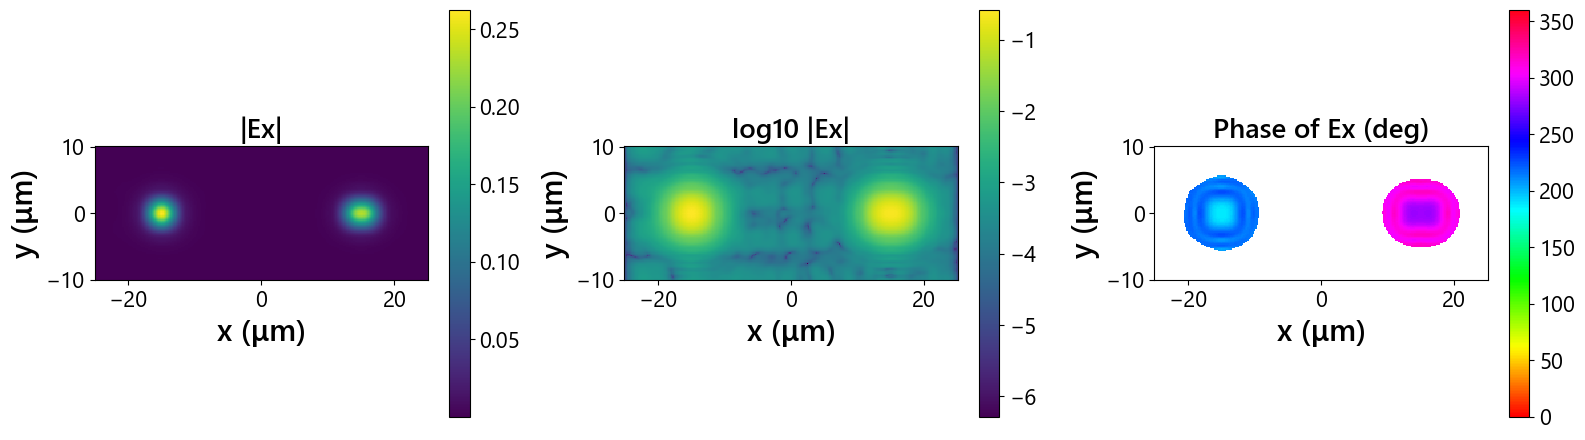

In [10]:
filename = 'D:\DATA\ActivePIC\AchromaticPhaseDelay\TwoWaveguideTest\FullWAVE_test_bpm_ex.dat'

def read_amp_phase(fn):
    """Read an RSoft OUTPUT_AMP_PHASE_3D file with no coordinate row.
    Returns x, y (1D) and amp, phase_deg as (ny, nx) arrays."""
    with open(fn) as f:
        lines = [ln for ln in f if ln.strip()]
    kw = next(i for i, ln in enumerate(lines) if "OUTPUT_" in ln)
    n1, x0, x1 = lines[kw].split()[:3]
    n2, y0, y1 = lines[kw + 1].split()[:3]
    n1, n2 = int(n1), int(n2)
    x = np.linspace(float(x0), float(x1), n1)
    y = np.linspace(float(y0), float(y1), n2)
    raw = np.array([[float(v) for v in ln.split()]
                    for ln in lines[kw + 2: kw + 2 + n1]])   # (n1, 2*n2)
    amp = raw[:, 0::2].T          # (ny, nx)
    phase_deg = raw[:, 1::2].T
    return x, y, amp, phase_deg

# fn = "your_Ex_file"               # <-- set to your file path
x, y, amp, ph = read_amp_phase(filename)

# Phase is meaningless where the field is ~0, so hide it below 1% of peak
ph_masked = np.ma.masked_where(amp < 0.01 * amp.max(), np.mod(ph, 360))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

im0 = axes[0].pcolormesh(x, y, amp, shading="auto", cmap="viridis")
axes[0].set_title("|Ex|")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].pcolormesh(x, y, np.log10(amp + 1e-30), shading="auto", cmap="viridis")
axes[1].set_title("log10 |Ex|")
fig.colorbar(im1, ax=axes[1])

im2 = axes[2].pcolormesh(x, y, ph_masked, shading="auto", cmap="hsv", vmin=0, vmax=360)
axes[2].set_title("Phase of Ex (deg)")
fig.colorbar(im2, ax=axes[2])

for ax in axes:
    ax.set_xlabel("x (\u03bcm)")
    ax.set_ylabel("y (\u03bcm)")
    ax.set_aspect("equal")

fig.tight_layout()
plt.show()

In [50]:
monitors

[array([  0.4918216, 208.8473   ,   0.485877 , 279.7306   ]),
 array([], dtype=float64),
 array([  0.4439029, 306.7464   ,   0.5457217,  14.80486  ]),
 array([  0.4449304, 188.9097   ,   0.5447987, 256.7867   ]),
 array([  0.4458902,  83.55943  ,   0.5438095, 151.2392   ]),
 array([  0.4467871, 350.2115   ,   0.5427511,  57.67864  ]),
 array([  0.4476146, 268.4066   ,   0.5416259, 335.6459   ]),
 array([  0.4483726, 197.7085   ,   0.5404338, 264.7051   ]),
 array([  0.4490618, 137.7025   ,   0.5391744, 204.4422   ]),
 array([  0.4496846,  87.99445  ,   0.537843 , 154.4633   ]),
 array([  0.4502687,  48.20961  ,   0.5364152, 114.3937   ])]

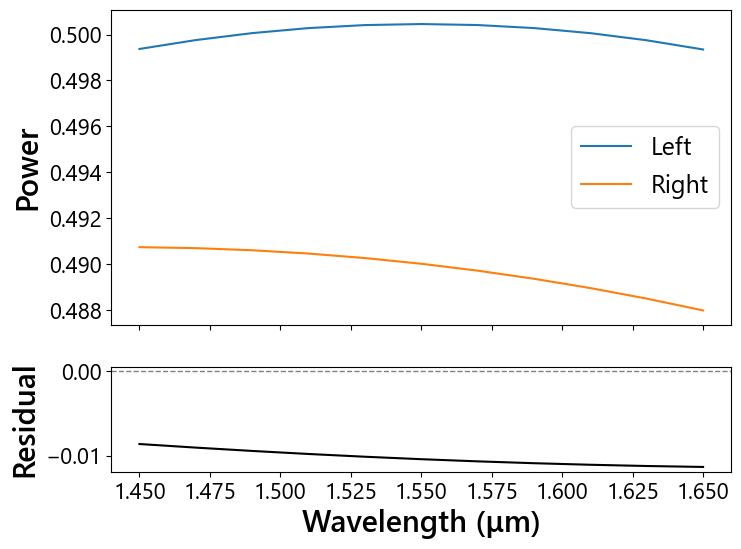

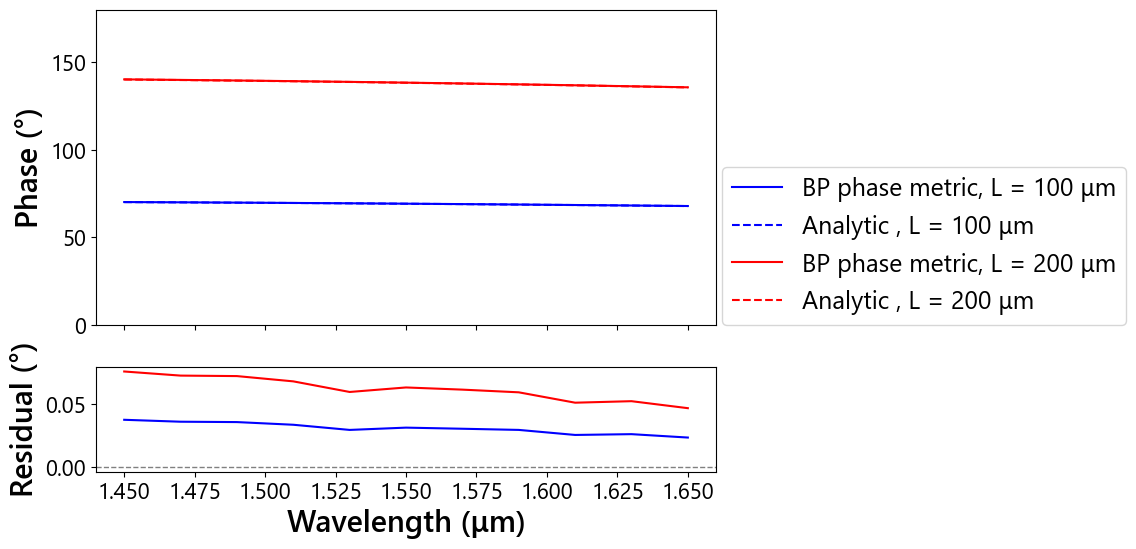

In [42]:
import pandas as pd

working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
filename_root = "TwoWaveguides_widthTest_widthTest"
prefix_root = f'{filename_root}_Length{Length}_scan_Wav'
save_dir = f"{working_dir}{prefix_root}\\"
table_filename = 'D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table\StraightWaveguide_neff_long_fullWavelengthRange.csv'
df_neff = pd.read_csv(table_filename)
wav_arr = np.linspace (1.45, 1.65, 11)

monitors_0, phase_diff_expected_0, monitors_1, phase_diff_expected_1 = [], [], [], []
for wav in wav_arr:
    match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], 3.40)]
    neff_left = match.iloc[0]['neff']
    match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], 5.0)]
    neff_right = match.iloc[0]['neff']
    phase_diff_expected_0.append((2*np.pi/wav * (neff_right - neff_left) * 100) * 180/np.pi)
    phase_diff_expected_1.append((2*np.pi/wav * (neff_right - neff_left) * 200) * 180/np.pi)

    wav_str = f"{wav:0.3f}".replace(".", "p")
    monitor_filename = f'{save_dir}{prefix_root}{wav_str}.mon'
    monitor = rlib.read_monitor(monitor_filename)
    # if np.isclose(wav, 1.45):
    #     test_grid = rlib.read_monitor(f'{save_dir}TwoWaveguides_widthTest_gridSize0p05_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon').values[-1]
    #     test_pade0 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_Direct_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon')
    #     test_pade0 = test_pade0.values[np.isclose(test_pade0.z, 100.0)].flatten()
    # if np.isclose(wav, 1.47):
    #     test_pade1 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_ADI_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon').values[-1]
        
    monitors_0.append(monitor.values[np.isclose(monitor.z, 100.0)].flatten())
    monitors_1.append(monitor.values[np.isclose(monitor.z, 200.0)].flatten())
monitors_0, monitors_1 = np.array(monitors_0), np.array(monitors_1)
phase_diff_expected_0, phase_diff_expected_1 = np.array(phase_diff_expected_0), np.array(phase_diff_expected_1)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(wav_arr, monitors[:,0], label='Left', color='C0')
ax1.plot(wav_arr, monitors[:,2], label='Right', color='C1')
ax1.set_ylabel('Power')
ax1.legend()
 
residual = monitors[:,2] - monitors[:,0]
ax2.plot(wav_arr, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual')
plt.show()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 

phase_diff_monitor_0 = (monitors_0[:,3] - monitors_0[:,1])%360
phase_diff_monitor_1 = (monitors_1[:,3] - monitors_1[:,1])%360
ax1.plot(wav_arr, phase_diff_monitor_0, 'b', label='BP phase metric, L = 100 μm')
ax1.plot(wav_arr, phase_diff_expected_0, 'b--', label='Analytic , L = 100 μm')
ax1.plot(wav_arr, phase_diff_monitor_1, 'r', label='BP phase metric, L = 200 μm')
ax1.plot(wav_arr, phase_diff_expected_1, 'r--', label='Analytic , L = 200 μm')
# ax1.plot([1.45], [test_grid[3]-test_grid[1]], color='C0', marker='o', label='BP, Grid size = 0.05 μm')
# ax1.plot([1.45], [test_pade0[3]-test_pade0[1]], color='C1', marker='.', label='BP, Pade order = (4, 4)')
# ax1.plot([1.47], [test_pade1[3]-test_pade1[1]], color='C1', marker='o', label='BP, Pade order = (4, 4)')
ax1.set_ylim(0, 180)
ax1.set_ylabel('Phase (°)')
ax1.legend(loc=(1.01, 0))
 
residual_0 = phase_diff_monitor_0 - phase_diff_expected_0
residual_0[residual_0 > 180] = residual_0[residual_0 > 180] - 360 
residual_0[residual_0 < -180] = residual_0[residual_0 < -180] + 360 
residual_1 = phase_diff_monitor_1 - phase_diff_expected_1
residual_1[residual_1 > 180] = residual_1[residual_1 > 180] - 360 
residual_1[residual_1 < -180] = residual_1[residual_1 < -180] + 360 
ax2.plot(wav_arr, residual_0, color='b')
ax2.plot(wav_arr, residual_1, color='r')
# ax2.plot(wav_arr, phase_diff_expected, color='k', linestyle='dashed')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual (°)')
 
# # Inset: zoom into the last 0.1 microns of z
# z_max = monitors.z.max()
# axins = inset_axes(ax1, width="35%", height="45%", loc='upper left', borderpad=2)
 
# mask = monitors.z >= (z_max - 0.1)
# axins.plot(monitors.z, residual, color='k')
# axins.axhline(0, color='grey', linestyle='dashed', linewidth=1)
# axins.set_xlim(z_max - 0.01, z_max+0.01)
# # axins.set_ylim(179, 181)
 
plt.show()


In [59]:

print(df_left, )

[[0.         1.45524395 0.        ]
 [1.         1.45523608 0.        ]] 1.455236077


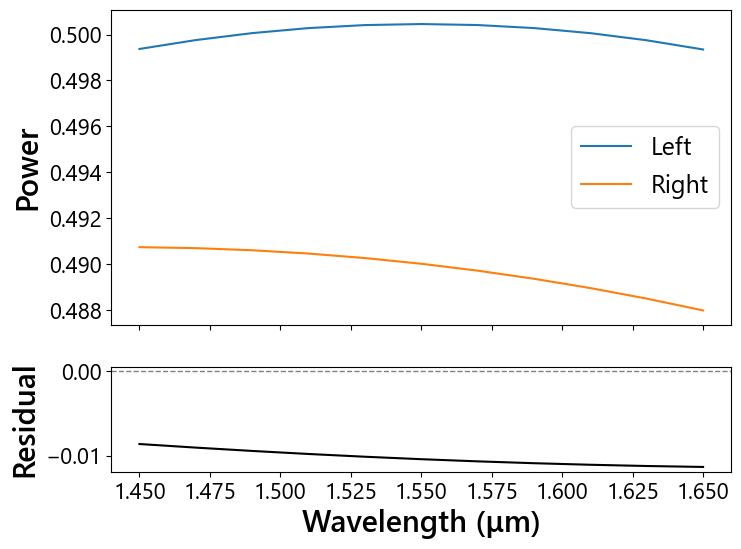

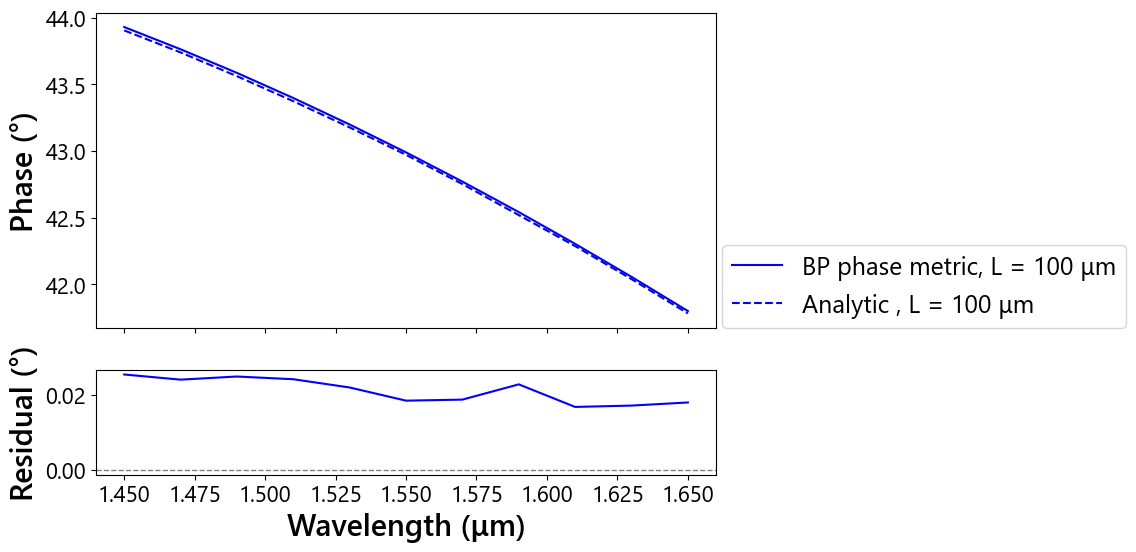

In [60]:
import pandas as pd

# Define parameter scan
wav_arr = np.linspace (1.45, 1.65, 11)
Left_width, Right_width = 3.3, 4.1
Left_width_str, Right_width_str = f"{Left_width:0.3f}".replace(".", "p"), f"{Right_width:0.3f}".replace(".", "p")

# Define directories and files to work with
working_dir = "D:\\DATA\\ActivePIC\\AchromaticPhaseDelay\\TwoWaveguideTest\\"
filename_root = "TwoWaveguides_widthTest"
Length = 100
prefix_root = f'{filename_root}_Left{Left_width_str}_Right{Right_width_str}_scan_Wav'
save_dir = f"{working_dir}{prefix_root}\\"
os.makedirs(save_dir, exist_ok=True)
filename = f"{filename_root}.ind"
table_filename = 'D:\DATA\ActivePIC\SingleWaveguideConvergence\StraightWaveguide_neff_table\StraightWaveguide_neff_long_fullWavelengthRange.csv'
df_neff = pd.read_csv(table_filename)

monitors_0, phase_diff_expected_0, monitors_1, phase_diff_expected_1 = [], [], [], []
for wav in wav_arr:
    wav_str = f"{wav:0.3f}".replace(".", "p")
    # match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], Left_width)]
    # neff_left = match.iloc[0]['neff']
    df_left = np.genfromtxt(f'D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_neff_table\\StraightWaveguide_Wav{wav_str}_Width3p300.nef')
    neff_left = df_left[1,1]
    match = df_neff[np.isclose(df_neff['wavelength'], wav) & np.isclose(df_neff['width'], Right_width)]
    neff_right = match.iloc[0]['neff']
    phase_diff_expected_0.append((2*np.pi/wav * (neff_right - neff_left) * 100) * 180/np.pi)
    # phase_diff_expected_1.append((2*np.pi/wav * (neff_right - neff_left) * 200) * 180/np.pi)

    monitor_filename = f'{save_dir}{prefix_root}{wav_str}.mon'
    monitor = rlib.read_monitor(monitor_filename)
    # if np.isclose(wav, 1.45):
    #     test_grid = rlib.read_monitor(f'{save_dir}TwoWaveguides_widthTest_gridSize0p05_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon').values[-1]
    #     test_pade0 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_Direct_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon')
    #     test_pade0 = test_pade0.values[np.isclose(test_pade0.z, 100.0)].flatten()
    # if np.isclose(wav, 1.47):
    #     test_pade1 = rlib.read_monitor(f'{working_dir}TwoWaveguides_widthTest_pade44_ADI_scan_Wav\\{filename_root}_widthTest_scan_Wav{wav_str}.mon').values[-1]
        
    monitors_0.append(monitor.values[np.isclose(monitor.z, 100.0)].flatten())
    # monitors_1.append(monitor.values[np.isclose(monitor.z, 200.0)].flatten())
monitors_0, monitors_1 = np.array(monitors_0), np.array(monitors_1)
phase_diff_expected_0, phase_diff_expected_1 = np.array(phase_diff_expected_0), np.array(phase_diff_expected_1)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 
ax1.plot(wav_arr, monitors[:,0], label='Left', color='C0')
ax1.plot(wav_arr, monitors[:,2], label='Right', color='C1')
ax1.set_ylabel('Power')
ax1.legend()
 
residual = monitors[:,2] - monitors[:,0]
ax2.plot(wav_arr, residual, color='k')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual')
plt.show()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
) 

phase_diff_monitor_0 = (monitors_0[:,3] - monitors_0[:,1])%360
# phase_diff_monitor_1 = (monitors_1[:,3] - monitors_1[:,1])%360
ax1.plot(wav_arr, phase_diff_monitor_0, 'b', label='BP phase metric, L = 100 μm')
ax1.plot(wav_arr, phase_diff_expected_0, 'b--', label='Analytic , L = 100 μm')
# ax1.plot(wav_arr, phase_diff_monitor_1, 'r', label='BP phase metric, L = 200 μm')
# ax1.plot(wav_arr, phase_diff_expected_1, 'r--', label='Analytic , L = 200 μm')
# ax1.plot([1.45], [test_grid[3]-test_grid[1]], color='C0', marker='o', label='BP, Grid size = 0.05 μm')
# ax1.plot([1.45], [test_pade0[3]-test_pade0[1]], color='C1', marker='.', label='BP, Pade order = (4, 4)')
# ax1.plot([1.47], [test_pade1[3]-test_pade1[1]], color='C1', marker='o', label='BP, Pade order = (4, 4)')
# ax1.set_ylim(0, 180)
ax1.set_ylabel('Phase (°)')
ax1.legend(loc=(1.01, 0))
 
residual_0 = phase_diff_monitor_0 - phase_diff_expected_0
residual_0[residual_0 > 180] = residual_0[residual_0 > 180] - 360 
residual_0[residual_0 < -180] = residual_0[residual_0 < -180] + 360 
# residual_1 = phase_diff_monitor_1 - phase_diff_expected_1
# residual_1[residual_1 > 180] = residual_1[residual_1 > 180] - 360 
# residual_1[residual_1 < -180] = residual_1[residual_1 < -180] + 360 
ax2.plot(wav_arr, residual_0, color='b')
# ax2.plot(wav_arr, residual_1, color='r')
# ax2.plot(wav_arr, phase_diff_expected, color='k', linestyle='dashed')
ax2.axhline(0, color='grey', linestyle='dashed', linewidth=1)
ax2.set_xlabel('Wavelength (μm)')
ax2.set_ylabel('Residual (°)')
 
# # Inset: zoom into the last 0.1 microns of z
# z_max = monitors.z.max()
# axins = inset_axes(ax1, width="35%", height="45%", loc='upper left', borderpad=2)
 
# mask = monitors.z >= (z_max - 0.1)
# axins.plot(monitors.z, residual, color='k')
# axins.axhline(0, color='grey', linestyle='dashed', linewidth=1)
# axins.set_xlim(z_max - 0.01, z_max+0.01)
# # axins.set_ylim(179, 181)
 
plt.show()
